# Robots from MuJoCo Menagerie

A model that already exists, such as a Panda or a Go1, is an `ExternalRobot`: a reference with the numbers the config needs. The `menagerie` robot provider reads them from the model,
the simulator attaches the model to the scene and drives it with **its own actuators**. This notebook describes a Panda and a Go1, steps each, spawns the Go1 at two mounts and shows a frame of each.

Needs `pip install 'robotdesigner[menagerie,viz]'`. The library fetches a model on first use and caches it outside the repository; nothing of a model is copied into it.

In [1]:
import io
import os
import sys

# Headless Linux (no DISPLAY, e.g. a cluster node): use EGL. This must happen before mujoco is imported;
# if mujoco was already imported in this kernel, set MUJOCO_GL=egl in the environment and restart the kernel.
if sys.platform == "linux" and not os.environ.get("DISPLAY"):
    os.environ.setdefault("MUJOCO_GL", "egl")

import numpy as np
import torch
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image

from robotdesigner.config import BaseEnvConfig, Pose
from robotdesigner.robot.providers.menagerie import PROVIDER


def show(image, quality=90):
    """Show an RGB array as one small JPEG (keeps the notebook file small)."""
    buf = io.BytesIO()
    Image.fromarray(image).save(buf, format="JPEG", quality=quality)
    display(IPImage(data=buf.getvalue(), format="jpeg"))

## 1. Describe two robots

`describe` opens the model and returns an `ExternalRobot`: the joints a controller drives (with ranges and effort limits), the home posture, the free root of a floating robot, the end effector,
and what kind of actuators the model has. `source` is the library's content id of the model; it is part of the hash, so a changed model is a different robot.

In [2]:
panda = PROVIDER.describe("franka_emika_panda")
go1 = PROVIDER.describe("unitree_go1")

for robot in (panda, go1):
    print(f"{robot.name:20} {robot.n:2} driven joints, {robot.actuator_kind:8} actuators, keyframe {robot.keyframe!r}, "
          f"free root: {robot.home_root is not None}, end effector: {robot.end_effector is not None}, licence {PROVIDER.license(robot.name)}")
print(panda.config_hash, go1.config_hash)

franka_emika_panda    7 driven joints, position actuators, keyframe 'home', free root: False, end effector: True, licence Apache-2.0
unitree_go1          12 driven joints, position actuators, keyframe 'home', free root: True, end effector: False, licence BSD-3-Clause
9a83c5f9525a 203d67d167e3


## 2. Run each for a few steps

The builder puts the robot in the config like any other. An external robot is driven with its own actuators unless you write other gains, so `explain()` marks the gains as coming from the robot.
The Panda's fingers are not driven: they are held at the keyframe's control. The Go1 is driven by `joint_pos_delta` here, and a zero action keeps the position targets at the reset pose, so it stands.

In [3]:
panda_env = BaseEnvConfig().robot(panda).sim(num_envs=2, scene="plain_floor").build()
print([line for line in BaseEnvConfig().robot(panda).explain().splitlines() if "control" in line or "license" in line])

td = panda_env.reset()
for _ in range(20):
    td["action"] = panda_env.action_spec.rand()
    td = panda_env.step(td)["next"]
print("panda end effector (base frame):", td["task"].keys() if "task" in td.keys() else "no task observation", td["proprio", "qpos"].shape)

["  robot.license           'Apache-2.0'  [provider]", "  control.mode            'joint_pos_abs'  [default]", '  control.gains           NativeGains()  [default (robot)]', '  control.action_scale    None  [default]', '  sim.control_freq        50.0  [default]']
panda end effector (base frame): _StringKeys(dict_keys([])) torch.Size([2, 7])


In [4]:
go1_cfg = BaseEnvConfig().robot(go1).control(mode="joint_pos_delta", action_scale=0.05).sim(num_envs=2, scene="plain_floor")
go1_env = go1_cfg.build()
td = go1_env.reset()
root = go1_env.interface.root_qpos_adr
for _ in range(100):                                                    # 2 s of control at 50 Hz
    td["action"] = torch.zeros(2, go1.n)
    td = go1_env.step(td)["next"]
print("go1 keyframe height:", go1.home_root.pos[2], " height after 2 s:", round(float(go1_env._sim.data[0].qpos[root + 2]), 3))

go1 keyframe height: 0.27  height after 2 s: 0.267


## 3. Spawn the Go1 at two mounts

The task's `mount` is where the model's world frame goes, so it is the spawn pose: the robot starts at the mount composed with the root pose of its keyframe. A mount above the floor makes it fall and land.

In [5]:
mounts = {
    "turned 90 degrees, shifted": Pose((0.4, -0.3, 0.0), (0.7071068, 0.0, 0.0, 0.7071068)),
    "0.3 m up": Pose((0.0, 0.0, 0.3), (1.0, 0.0, 0.0, 0.0)),
}
envs = {}
for label, mount in mounts.items():
    env = go1_cfg.task(mount=mount).sim(num_envs=1).build()
    env.reset()
    a = env.interface.root_qpos_adr
    print(f"{label:28} root at {np.round(env._sim.data[0].qpos[a:a + 3], 3)}")
    envs[label] = env

turned 90 degrees, shifted   root at [ 0.4  -0.3   0.27]


0.3 m up                     root at [0.   0.   0.57]


## 4. A frame of each

panda (240, 320, 3) uint8


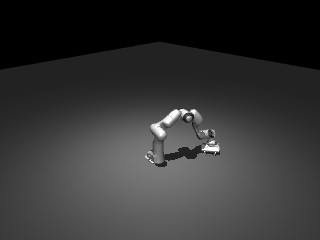

go1 after the drop (240, 320, 3) uint8


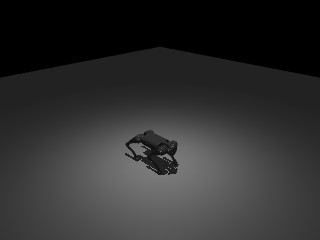

go1 turned and shifted (240, 320, 3) uint8


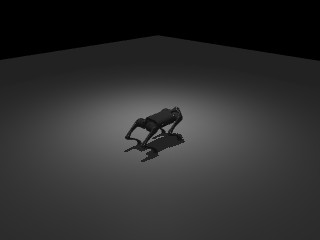

In [6]:
frames = {"panda": panda_env.render(size=(240, 320))}
td = envs["0.3 m up"].reset()
for _ in range(75):                                                     # let it land
    td["action"] = torch.zeros(1, go1.n)
    td = envs["0.3 m up"].step(td)["next"]
frames["go1 after the drop"] = envs["0.3 m up"].render(size=(240, 320))
frames["go1 turned and shifted"] = envs["turned 90 degrees, shifted"].render(size=(240, 320))
for name, frame in frames.items():
    print(name, frame.shape, frame.dtype)
    show(frame)